Import Libraries

In [4]:
# =============================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Splitting and Cross Validation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    cross_val_score
)

# Machine Learning Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# Feature Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model Evaluation
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import warnings
warnings.filterwarnings("ignore")

# Plot Settings
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["font.size"] = 11

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


Loading the Dataset

In [5]:
# =============================================
# STEP 2: LOAD HEAVY VEHICLE DATASET
# =============================================

file_path = r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\Vehicle Class wise\Heavy Vehicle_165.xlsx"

df = pd.read_excel(file_path)

print("Dataset Loaded Successfully!")

print("\nDataset Shape:", df.shape)

print("\nFirst Five Observations:")

display(df.head())

Dataset Loaded Successfully!

Dataset Shape: (165, 10)

First Five Observations:


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
0,1,48.0,1.27,inf,5.5,0.9,Gravel,0.9,Gravel,3.70
1,2,28.8,2.92,46.0,5.5,0.9,Gravel,0.9,Gravel,4.51
2,3,44.5,7.97,inf,5.5,0.9,Gravel,0.9,Gravel,4.39
3,4,32.8,2.07,inf,5.5,0.9,Gravel,0.9,Gravel,4.69
4,5,26.7,1.21,16.0,5.5,0.9,Gravel,0.9,Gravel,5.57


Checking Column Names

In [6]:
# =============================================
# STEP 3: CHECK COLUMN NAMES
# =============================================

print("Column Names:")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Column Names:
1. SN
2. V85 Speed
3. Gradient
4. Radius of Curve
5. Carriageway Width
6. Left Shoulder Width
7. Left Shoulder Type
8. Right Shoulder Width
9. Right Shoulder Type
10. IRI


Dataset Information

In [7]:
# =============================================
# STEP 4: DATASET INFORMATION
# =============================================

print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nMISSING VALUES")
print("=" * 50)

print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print("=" * 50)

print(df.duplicated().sum())

print("\nDATASET DIMENSIONS")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SN                    165 non-null    int64  
 1   V85 Speed             165 non-null    float64
 2   Gradient              165 non-null    float64
 3   Radius of Curve       165 non-null    float64
 4   Carriageway Width     165 non-null    float64
 5   Left Shoulder Width   165 non-null    float64
 6   Left Shoulder Type    165 non-null    str    
 7   Right Shoulder Width  165 non-null    float64
 8   Right Shoulder Type   165 non-null    str    
 9   IRI                   165 non-null    float64
dtypes: float64(7), int64(1), str(2)
memory usage: 13.0 KB

MISSING VALUES
SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Wi

Identifying Zero Speed Observations

In [8]:
# =============================================
# STEP 5: IDENTIFY ZERO SPEED OBSERVATIONS
# =============================================

zero_speed_data = df[df["V85 Speed"] == 0]

print("Number of Zero-Speed Observations:",
      len(zero_speed_data))

print("\nZero-Speed Observations:")

display(zero_speed_data)

Number of Zero-Speed Observations: 5

Zero-Speed Observations:


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
18,19,0.0,3.80,inf,5.240,0.59,Paved,0.00,Absent,4.95
19,20,0.0,6.00,55.0,5.460,0.00,Absent,1.18,Gravel,5.94
20,21,0.0,7.90,60.0,4.914,0.40,Paved,0.40,Gravel,4.20
23,24,0.0,4.09,15.0,5.366,0.54,Paved,0.32,Gravel,4.14
25,26,0.0,5.50,30.0,5.084,0.99,Gravel,0.57,Gravel,4.24


Removing Zero Speed Observations

In [9]:
# =============================================
# STEP 6: EXCLUDE ZERO SPEED OBSERVATIONS
# =============================================

df_clean = df[df["V85 Speed"] > 0].copy()

print("Original Observations:", len(df))

print("Zero-Speed Observations:",
      len(zero_speed_data))

print("Remaining Observations:",
      len(df_clean))

Original Observations: 165
Zero-Speed Observations: 5
Remaining Observations: 160


Treatment of Infinity Radius

In [10]:
# =============================================
# STEP 7: CHECK INFINITY RADIUS
# =============================================

print("Infinity Radius Values Before Replacement:")

print(
    np.isinf(df_clean["Radius of Curve"]).sum()
)

Infinity Radius Values Before Replacement:
44


In [11]:
# Replace Infinity with 1500 m

df_clean["Radius of Curve"] = (
    df_clean["Radius of Curve"]
    .replace([np.inf, -np.inf], 1500)
)

print("Infinity Radius Values After Replacement:")

print(
    np.isinf(df_clean["Radius of Curve"]).sum()
)

Infinity Radius Values After Replacement:
0


In [12]:
# =============================================
# VIF ANALYSIS FOR ALL INDEPENDENT VARIABLES
# =============================================

import numpy as np
import pandas as pd

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Copy original dataset
df_vif = df.copy()

# Exclude zero-speed observations
df_vif = df_vif[df_vif["V85 Speed"] > 0].copy()

# Replace infinity radius with 1500 m
df_vif["Radius of Curve"] = pd.to_numeric(
    df_vif["Radius of Curve"].replace("infinity", 1500),
    errors="coerce"
)

df_vif["Radius of Curve"] = df_vif[
    "Radius of Curve"
].replace([np.inf, -np.inf], 1500)

# Clean shoulder type categories
df_vif["Left Shoulder Type"] = (
    df_vif["Left Shoulder Type"].astype(str).str.strip()
)

df_vif["Right Shoulder Type"] = (
    df_vif["Right Shoulder Type"].astype(str).str.strip()
)

# Select all original independent variables
X_vif = df_vif[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Left Shoulder Width",
        "Left Shoulder Type",
        "Right Shoulder Width",
        "Right Shoulder Type",
        "IRI"
    ]
].copy()

# Convert categorical variables into dummy variables
X_vif = pd.get_dummies(
    X_vif,
    columns=[
        "Left Shoulder Type",
        "Right Shoulder Type"
    ],
    drop_first=True,
    dtype=int
)

# Add constant for VIF calculation
X_vif_const = add_constant(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values.astype(float),
        i
    )
    for i in range(1, X_vif_const.shape[1])
]

# Sort by highest VIF
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

print("VIF Analysis - All Independent Variables")

display(vif_data.round(3))

VIF Analysis - All Independent Variables


,Variable,VIF
6,Left Shoulder Type_Gravel,8.959
9,Right Shoulder Type_Paved,8.930
7,Left Shoulder Type_Paved,8.774
3,Left Shoulder Width,7.670
8,Right Shoulder Type_Gravel,7.355
4,Right Shoulder Width,6.679
5,IRI,1.831
2,Carriageway Width,1.234
0,Gradient,1.127
1,Radius of Curve,1.118


In [13]:
# =============================================
# VIF ANALYSIS WITH AVERAGE SHOULDER WIDTH
# =============================================

import pandas as pd
import numpy as np

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Calculate Average Shoulder Width
df_clean["Average Shoulder Width"] = (
    df_clean["Left Shoulder Width"] +
    df_clean["Right Shoulder Width"]
) / 2

# Select five independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

X_vif = df_clean[features].copy()

# Add intercept
X_vif_const = add_constant(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = features

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values.astype(float), i
    )
    for i in range(1, X_vif_const.shape[1])
]

# Sort by VIF
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

print("VIF Analysis with Average Shoulder Width")

display(vif_data.round(3))

VIF Analysis with Average Shoulder Width


,Variable,VIF
4,IRI,1.767
3,Average Shoulder Width,1.574
2,Carriageway Width,1.128
0,Gradient,1.064
1,Radius of Curve,1.062


In [14]:
# =============================================
# STEP 14: FINAL FEATURE SELECTION
# =============================================

# Define the final independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Define the dependent variable
target = "V85 Speed"

# Create final modeling dataset
df_model = df_clean[
    ["SN"] + features + [target]
].copy()

# Define independent variables (X)
X = df_model[features]

# Define dependent variable (y)
y = df_model[target]

# Display dataset information
print("FINAL FEATURE SELECTION")
print("=" * 50)

print("\nSelected Independent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(target)

print("\nTotal Observations:", len(df_model))
print("Number of Independent Variables:", X.shape[1])

print("\nFinal Modeling Dataset:")
display(df_model.head())

# Check missing and infinite values
assert X.notna().all().all(), "Missing predictor values found"
assert np.isfinite(X.to_numpy(dtype=float)).all(), "Invalid predictor values found"
assert y.notna().all(), "Missing target values found"
assert np.isfinite(y.to_numpy(dtype=float)).all(), "Invalid target values found"

FINAL FEATURE SELECTION

Selected Independent Variables:
['Gradient', 'Radius of Curve', 'Carriageway Width', 'Average Shoulder Width', 'IRI']

Dependent Variable:
V85 Speed

Total Observations: 160
Number of Independent Variables: 5

Final Modeling Dataset:


,SN,Gradient,Radius of Curve,Carriageway Width,Average Shoulder Width,IRI,V85 Speed
0,1,1.27,1500.0,5.5,0.9,3.70,48.0
1,2,2.92,46.0,5.5,0.9,4.51,28.8
2,3,7.97,1500.0,5.5,0.9,4.39,44.5
3,4,2.07,1500.0,5.5,0.9,4.69,32.8
4,5,1.21,16.0,5.5,0.9,5.57,26.7


In [15]:
# =============================================
# STEP 15: DESCRIPTIVE STATISTICAL ANALYSIS
# =============================================

# Select final modeling variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

target = "V85 Speed"

# Calculate descriptive statistics
descriptive_stats = df_model[
    features + [target]
].describe().T

# Rename columns
descriptive_stats = descriptive_stats.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std. Deviation",
    "min": "Minimum",
    "25%": "25th Percentile",
    "50%": "Median",
    "75%": "75th Percentile",
    "max": "Maximum"
})

print("DESCRIPTIVE STATISTICS - HEAVY VEHICLES")

display(descriptive_stats.round(3))

DESCRIPTIVE STATISTICS - HEAVY VEHICLES


,Count,Mean,Std. Deviation,Minimum,25th Percentile,Median,75th Percentile,Maximum
Gradient,160.0,4.059,2.512,0.07,1.743,4.035,6.027,11.085
Radius of Curve,160.0,470.419,639.475,15.00,35.000,75.500,1500.000,1500.000
Carriageway Width,160.0,6.359,0.885,4.70,5.500,7.000,7.000,8.000
Average Shoulder Width,160.0,0.630,0.352,0.00,0.250,0.635,1.000,1.030
IRI,160.0,5.961,2.666,2.15,3.575,5.485,8.572,12.050
V85 Speed,160.0,38.615,8.330,23.00,32.400,37.900,44.025,58.900


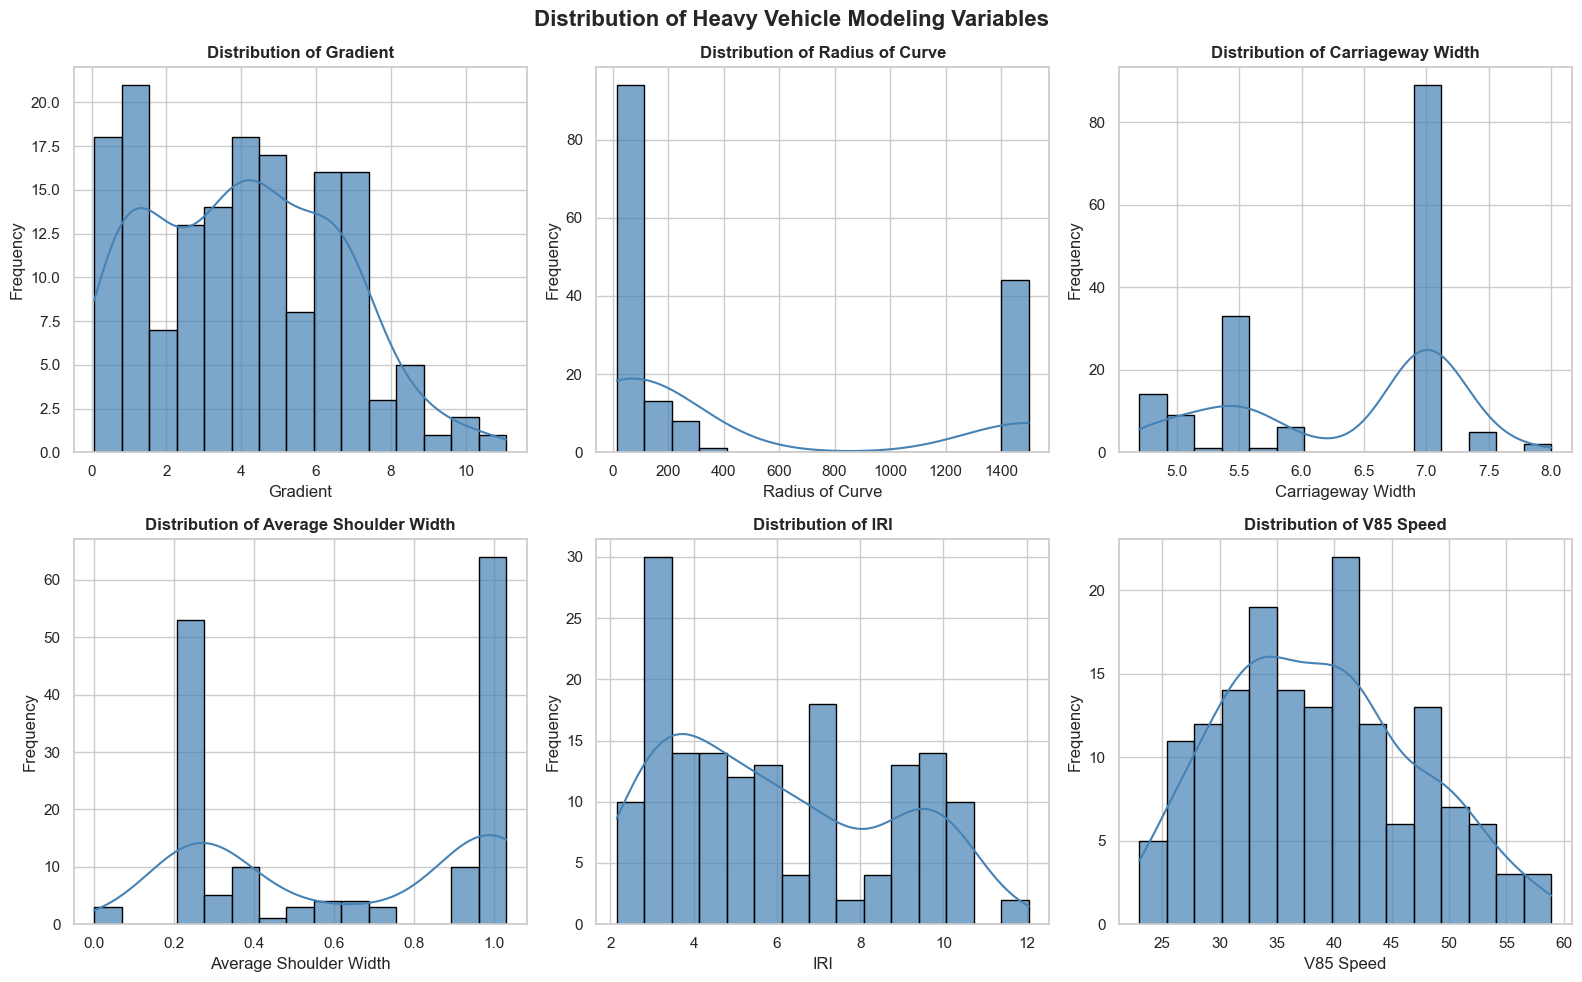

In [16]:
# =============================================
# STEP 16: DISTRIBUTION PLOTS
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Final selected variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

target = "V85 Speed"

variables = features + [target]

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, variable in enumerate(variables):

    sns.histplot(
        data=df_model,
        x=variable,
        bins=15,
        kde=True,
        ax=axes[i],
        color="steelblue",
        edgecolor="black",
        alpha=0.7
    )

    axes[i].set_title(
        f"Distribution of {variable}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Heavy Vehicle Modeling Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

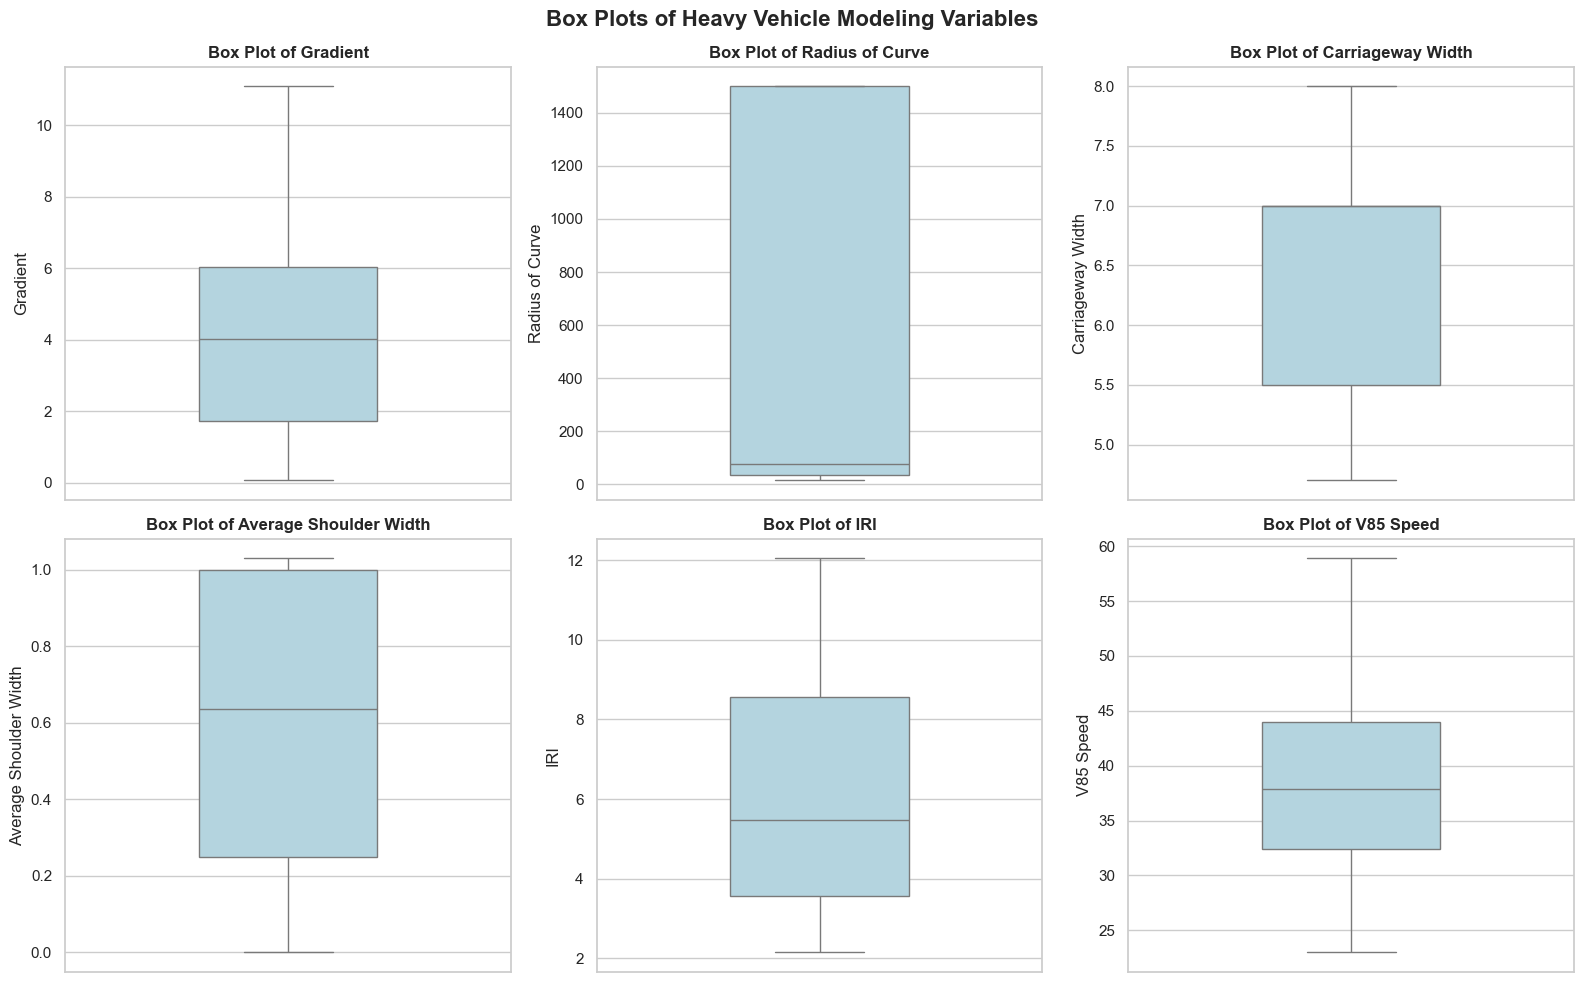

In [17]:
# =============================================
# STEP 17: BOX PLOTS
# =============================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, variable in enumerate(variables):

    sns.boxplot(
        y=df_model[variable],
        ax=axes[i],
        color="lightblue",
        width=0.4,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markerfacecolor": "red",
            "markersize": 5,
            "markeredgecolor": "black"
        }
    )

    axes[i].set_title(
        f"Box Plot of {variable}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_ylabel(variable)

plt.suptitle(
    "Box Plots of Heavy Vehicle Modeling Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [18]:
# =============================================
# IQR-BASED OUTLIER IDENTIFICATION
# =============================================

outlier_results = []

for variable in variables:

    Q1 = df_model[variable].quantile(0.25)
    Q3 = df_model[variable].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_model[
        (df_model[variable] < lower_bound) |
        (df_model[variable] > upper_bound)
    ]

    outlier_results.append({
        "Variable": variable,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": len(outliers)
    })

outlier_table = pd.DataFrame(outlier_results)

print("IQR-BASED POTENTIAL OUTLIERS")

display(outlier_table.round(3))

IQR-BASED POTENTIAL OUTLIERS


,Variable,Lower Bound,Upper Bound,Potential Outliers
0,Gradient,-4.685,12.455,0
1,Radius of Curve,-2162.500,3697.500,0
2,Carriageway Width,3.250,9.250,0
3,Average Shoulder Width,-0.875,2.125,0
4,IRI,-3.921,16.069,0
5,V85 Speed,14.963,61.462,0


In [19]:
# =============================================
# STEP 18: SKEWNESS ANALYSIS
# =============================================

# Calculate skewness
skewness_values = df_model[variables].skew()

# Create table
skewness_table = pd.DataFrame({
    "Variable": skewness_values.index,
    "Skewness": skewness_values.values
})

# Classify skewness
def classify_skewness(value):

    if abs(value) < 0.5:
        return "Approximately Symmetric"

    elif abs(value) < 1:
        return "Moderately Skewed"

    else:
        return "Highly Skewed"

skewness_table["Interpretation"] = (
    skewness_table["Skewness"].apply(classify_skewness)
)

print("SKEWNESS ANALYSIS - HEAVY VEHICLES")

display(skewness_table.round(3))

SKEWNESS ANALYSIS - HEAVY VEHICLES


,Variable,Skewness,Interpretation
0,Gradient,0.263,Approximately Symmetric
1,Radius of Curve,0.984,Moderately Skewed
2,Carriageway Width,-0.527,Moderately Skewed
3,Average Shoulder Width,-0.078,Approximately Symmetric
4,IRI,0.401,Approximately Symmetric
5,V85 Speed,0.306,Approximately Symmetric


PEARSON CORRELATION MATRIX


,Gradient,Radius of Curve,Carriageway Width,Average Shoulder Width,IRI,V85 Speed
Gradient,1.000,-0.171,-0.134,-0.021,-0.126,-0.220
Radius of Curve,-0.171,1.000,0.018,-0.083,0.181,0.469
Carriageway Width,-0.134,0.018,1.000,-0.075,0.297,0.208
Average Shoulder Width,-0.021,-0.083,-0.075,1.000,-0.588,-0.038
IRI,-0.126,0.181,0.297,-0.588,1.000,0.227
V85 Speed,-0.220,0.469,0.208,-0.038,0.227,1.000


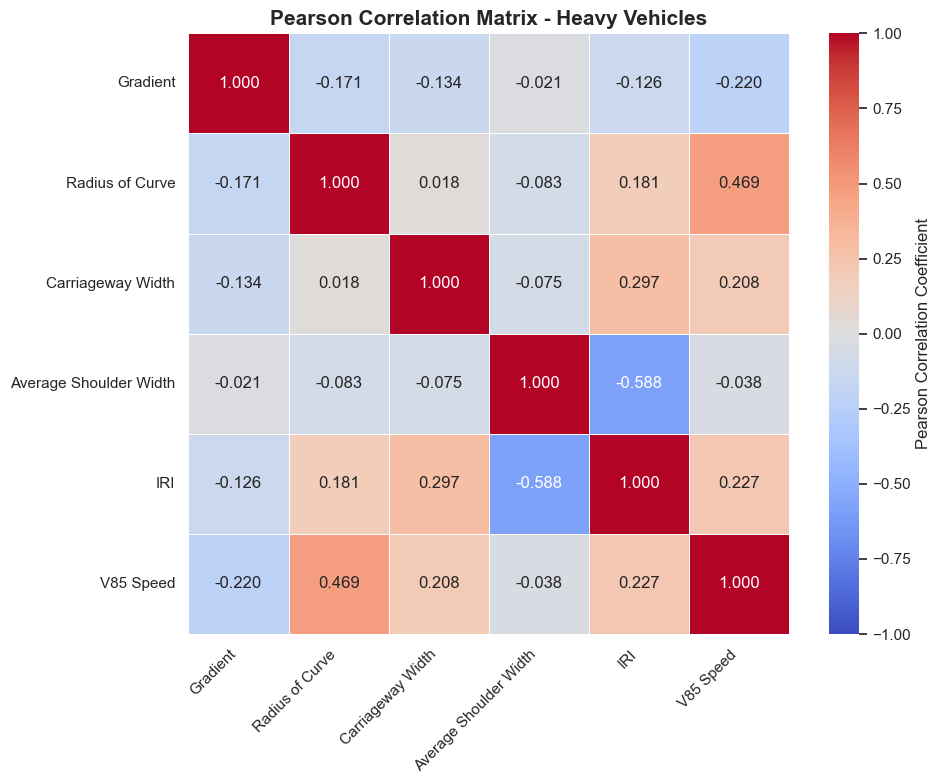

In [20]:
# =============================================
# STEP 19: PEARSON CORRELATION MATRIX
# =============================================

# Calculate correlation matrix
correlation_matrix = df_model[variables].corr(
    method="pearson"
)

# Display numerical values
print("PEARSON CORRELATION MATRIX")

display(correlation_matrix.round(3))

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Pearson Correlation Matrix - Heavy Vehicles",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [21]:
# =============================================
# CORRELATION WITH V85 SPEED
# =============================================

speed_correlation = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
)

correlation_table = pd.DataFrame({
    "Variable": speed_correlation.index,
    "Pearson r": speed_correlation.values
})

print("CORRELATION WITH HEAVY VEHICLE V85 SPEED")

display(correlation_table.round(3))

CORRELATION WITH HEAVY VEHICLE V85 SPEED


,Variable,Pearson r
0,Radius of Curve,0.469
1,IRI,0.227
2,Carriageway Width,0.208
3,Average Shoulder Width,-0.038
4,Gradient,-0.220


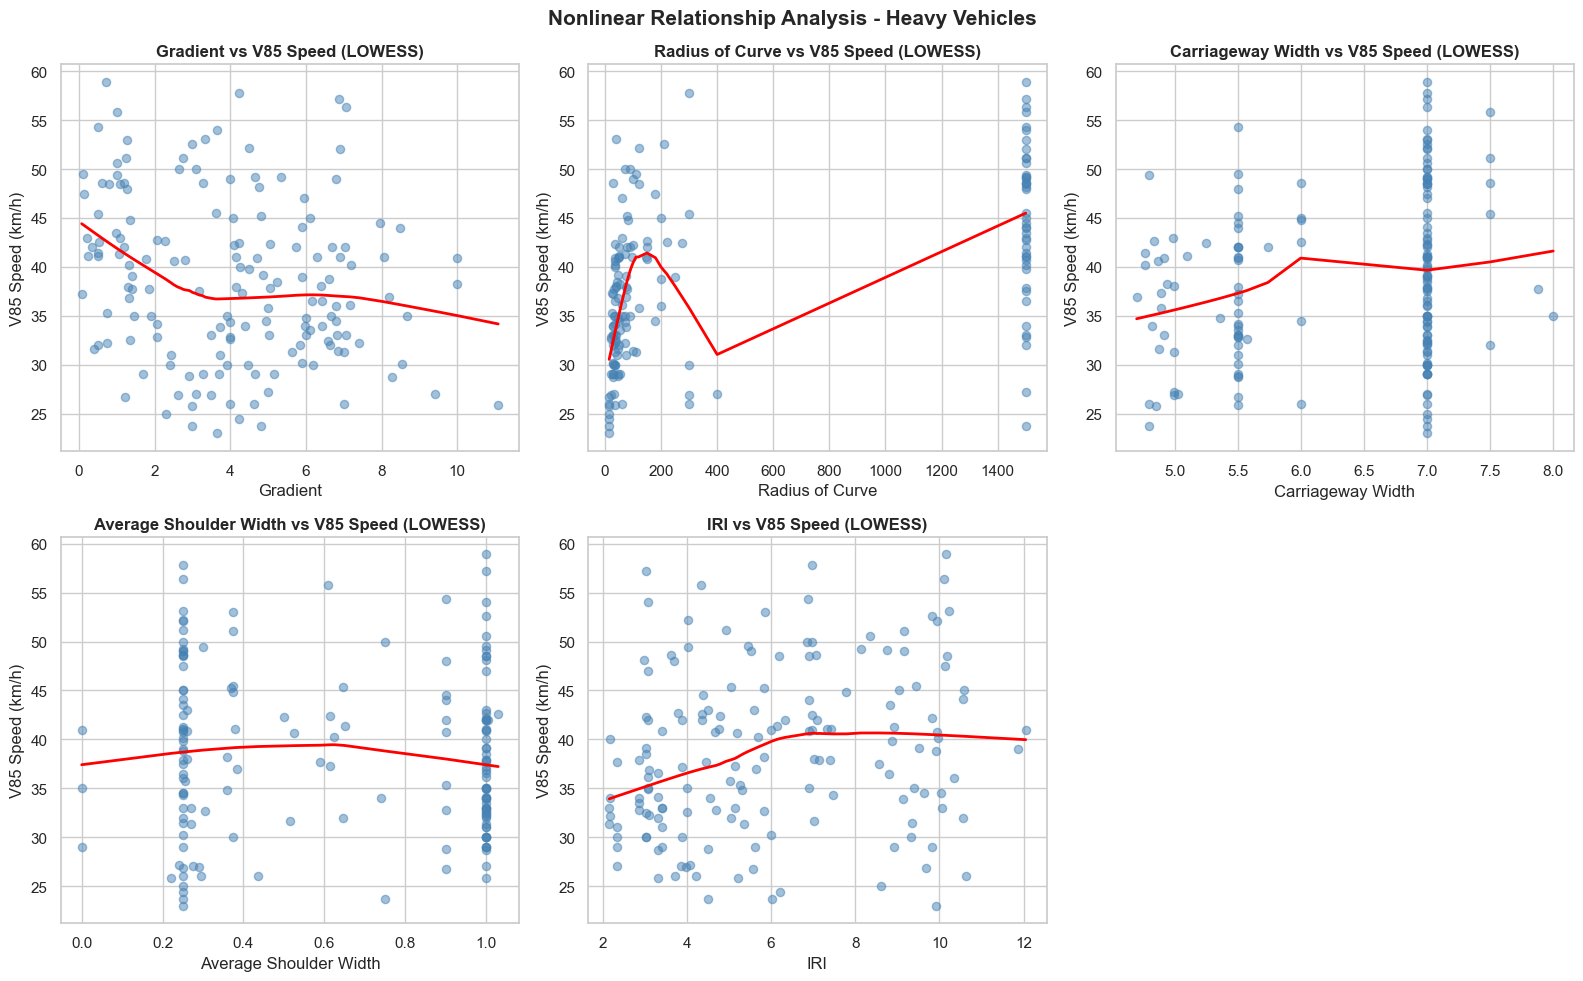

In [22]:
# =============================================
# STEP 21: NONLINEAR RELATIONSHIP PLOTS
# =============================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, feature in enumerate(features):

    sns.regplot(
        data=df_model,
        x=feature,
        y="V85 Speed",
        ax=axes[i],

        lowess=True,

        scatter_kws={
            "alpha": 0.5,
            "color": "steelblue",
            "s": 35
        },

        line_kws={
            "color": "red",
            "linewidth": 2
        }
    )

    axes[i].set_title(
        f"{feature} vs V85 Speed (LOWESS)",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("V85 Speed (km/h)")

fig.delaxes(axes[5])

plt.suptitle(
    "Nonlinear Relationship Analysis - Heavy Vehicles",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [23]:
# =============================================
# STEP 23: TRAIN-TEST SPLITTING
# =============================================

from sklearn.model_selection import train_test_split

# Define independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Define dependent variable
target = "V85 Speed"

# Independent variables
X = df_model[features]

# Dependent variable
y = df_model[target]

# Split dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display results
print("TRAIN-TEST SPLITTING")
print("=" * 50)

print("Total Observations:", len(X))
print("Training Observations:", len(X_train))
print("Testing Observations:", len(X_test))

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

TRAIN-TEST SPLITTING
Total Observations: 160
Training Observations: 128
Testing Observations: 32

Training Features Shape: (128, 5)
Testing Features Shape: (32, 5)

Training Target Shape: (128,)
Testing Target Shape: (32,)


In [24]:
# =============================================
# STEP 24.1: MULTIPLE LINEAR REGRESSION MODEL
# =============================================

from sklearn.linear_model import LinearRegression

# Initialize MLR model
mlr = LinearRegression()

# Train the model
mlr.fit(X_train, y_train)

print("MLR Model Trained Successfully!")

MLR Model Trained Successfully!


In [25]:
# =============================================
# STEP 24.2: MLR PREDICTIONS
# =============================================

# Training predictions
y_train_pred_mlr = mlr.predict(X_train)

# Testing predictions
y_test_pred_mlr = mlr.predict(X_test)

print("MLR Predictions Completed!")

# Compare actual and predicted testing speeds
mlr_predictions = pd.DataFrame({
    "Actual V85": y_test.values,
    "Predicted V85": y_test_pred_mlr
})

display(mlr_predictions.head(10).round(3))

MLR Predictions Completed!


,Actual V85,Predicted V85
0,43.50,47.283
1,29.00,39.135
2,35.00,36.814
3,49.50,36.178
4,23.00,39.109
5,27.20,41.522
6,31.45,38.936
7,39.10,40.049
8,39.80,46.897
9,42.00,36.389


In [26]:
# =============================================
# STEP 24.3: MLR MODEL EVALUATION
# =============================================

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import numpy as np
import pandas as pd

# Training Performance
train_r2 = r2_score(y_train, y_train_pred_mlr)

train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_mlr)
)

train_mae = mean_absolute_error(
    y_train, y_train_pred_mlr
)

# Testing Performance
test_r2 = r2_score(y_test, y_test_pred_mlr)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_mlr)
)

test_mae = mean_absolute_error(
    y_test, y_test_pred_mlr
)

# Create Performance Table
mlr_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R2": [train_r2, test_r2],
    "RMSE (km/h)": [train_rmse, test_rmse],
    "MAE (km/h)": [train_mae, test_mae]
})

print("MLR MODEL PERFORMANCE - HEAVY VEHICLES")

display(mlr_results.round(4))

MLR MODEL PERFORMANCE - HEAVY VEHICLES


,Dataset,R2,RMSE (km/h),MAE (km/h)
0,Training,0.2685,7.0570,5.6814
1,Testing,0.2871,7.1659,5.8667


In [27]:
# =============================================
# STEP 24.4: MLR COEFFICIENTS
# =============================================

# Extract coefficients
mlr_coefficients = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": mlr.coef_
})

# Display intercept
print("MLR Intercept:", round(mlr.intercept_, 4))

print("\nMLR Regression Coefficients:")

display(mlr_coefficients.round(4))

MLR Intercept: 24.1111

MLR Regression Coefficients:


,Variable,Coefficient
0,Gradient,-0.1148
1,Radius of Curve,0.0057
2,Carriageway Width,1.4657
3,Average Shoulder Width,0.7113
4,IRI,0.4932


In [28]:
# =============================================
# GENERATE MLR EQUATION
# =============================================

equation = f"V85 = {mlr.intercept_:.4f}"

for feature, coefficient in zip(X_train.columns, mlr.coef_):
    equation += f" {coefficient:+.4f} × ({feature})"

print("MLR Regression Equation:")
print(equation)

MLR Regression Equation:
V85 = 24.1111 -0.1148 × (Gradient) +0.0057 × (Radius of Curve) +1.4657 × (Carriageway Width) +0.7113 × (Average Shoulder Width) +0.4932 × (IRI)


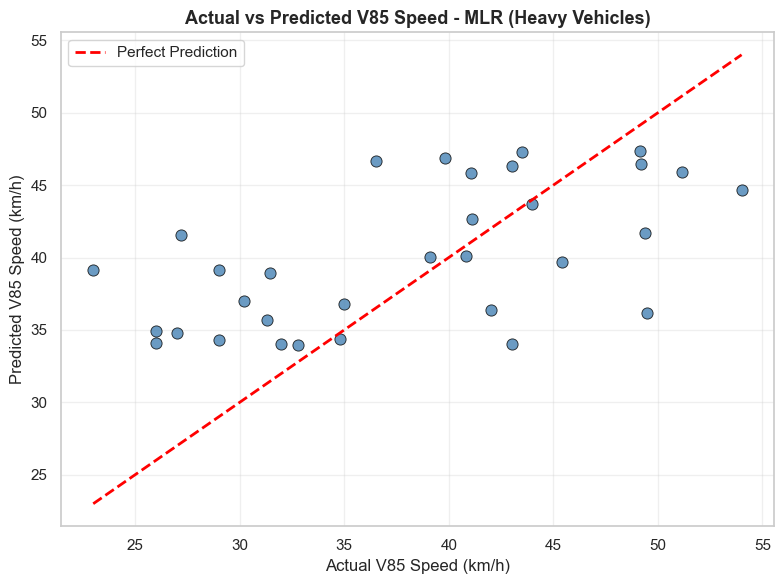

In [29]:
# =============================================
# STEP 24.5: ACTUAL VS PREDICTED PLOT
# =============================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_mlr,
    color="steelblue",
    s=65,
    alpha=0.8,
    edgecolor="black"
)

# Perfect prediction line
plot_min = min(y_test.min(), y_test_pred_mlr.min())
plot_max = max(y_test.max(), y_test_pred_mlr.max())

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Actual vs Predicted V85 Speed - MLR (Heavy Vehicles)",
    fontsize=13,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

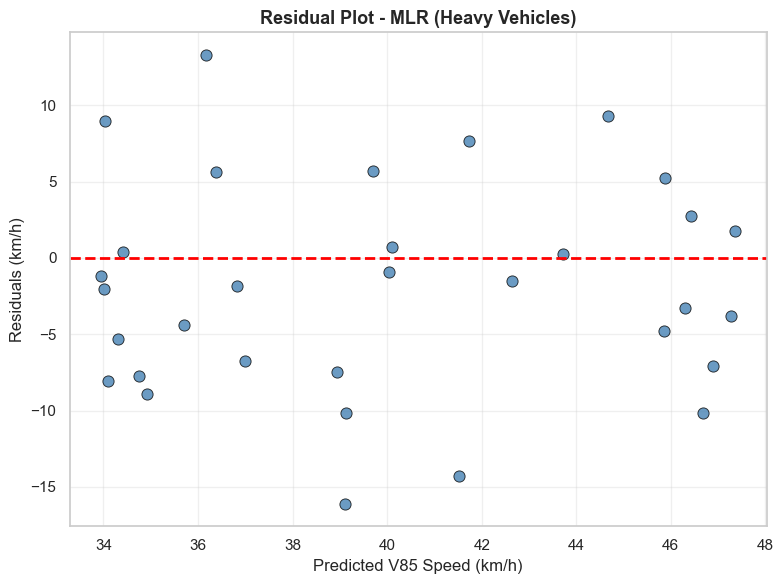

In [30]:
# =============================================
# STEP 24.6: RESIDUAL ANALYSIS
# =============================================

# Calculate testing residuals
mlr_residuals = y_test - y_test_pred_mlr

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test_pred_mlr,
    y=mlr_residuals,
    color="steelblue",
    s=65,
    alpha=0.8,
    edgecolor="black"
)

# Zero residual reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "Residual Plot - MLR (Heavy Vehicles)",
    fontsize=13,
    fontweight="bold"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# =============================================
# STEP 24.7: FIVE-FOLD CROSS-VALIDATION
# =============================================

from sklearn.model_selection import KFold, cross_val_score

# Define cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate RMSE for each fold
mlr_cv_scores = cross_val_score(
    mlr,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

# Convert negative scores to positive RMSE
mlr_cv_rmse = -mlr_cv_scores

print("MLR Five-Fold Cross-Validation Results")

for i, score in enumerate(mlr_cv_rmse, start=1):
    print(f"Fold {i} RMSE: {score:.4f} km/h")

print("\nMean CV RMSE:", round(mlr_cv_rmse.mean(), 4))

print(
    "Standard Deviation:",
    round(mlr_cv_rmse.std(ddof=1), 4)
)

MLR Five-Fold Cross-Validation Results
Fold 1 RMSE: 8.2146 km/h
Fold 2 RMSE: 6.8847 km/h
Fold 3 RMSE: 6.3543 km/h
Fold 4 RMSE: 9.0139 km/h
Fold 5 RMSE: 7.2280 km/h

Mean CV RMSE: 7.5391
Standard Deviation: 1.0677


In [32]:
# =============================================
# STEP 24.8: STORE MLR RESULTS
# =============================================

model_results = {}

model_results["MLR"] = {
    "Train R2": train_r2,
    "Test R2": test_r2,
    "Train RMSE": train_rmse,
    "Test RMSE": test_rmse,
    "Train MAE": train_mae,
    "Test MAE": test_mae,
    "CV RMSE": mlr_cv_rmse.mean(),
    "CV RMSE SD": mlr_cv_rmse.std(ddof=1)
}

print("MLR results stored successfully!")

MLR results stored successfully!


In [59]:
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [60]:
grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid_rf,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

# Best model

best_rf = grid_rf.best_estimator_

print("Best RF Parameters:")
print(grid_rf.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-grid_rf.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best RF Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation RMSE:
6.883779857150887


In [61]:
# Predictions

y_pred_rf = best_rf.predict(X_test)

# Evaluation metrics

r2_rf = r2_score(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("Tuned Random Forest Results")
print("----------------------------")
print(f"R²   : {r2_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f} km/h")
print(f"MAE  : {mae_rf:.4f} km/h")

Tuned Random Forest Results
----------------------------
R²   : 0.4191
RMSE : 6.4686 km/h
MAE  : 5.2704 km/h


In [62]:
rf_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_rf.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print(rf_importance)

                  Feature  Importance
1         Radius of Curve    0.404531
4                     IRI    0.229735
0                Gradient    0.216645
2       Carriageway Width    0.077934
3  Average Shoulder Width    0.071155


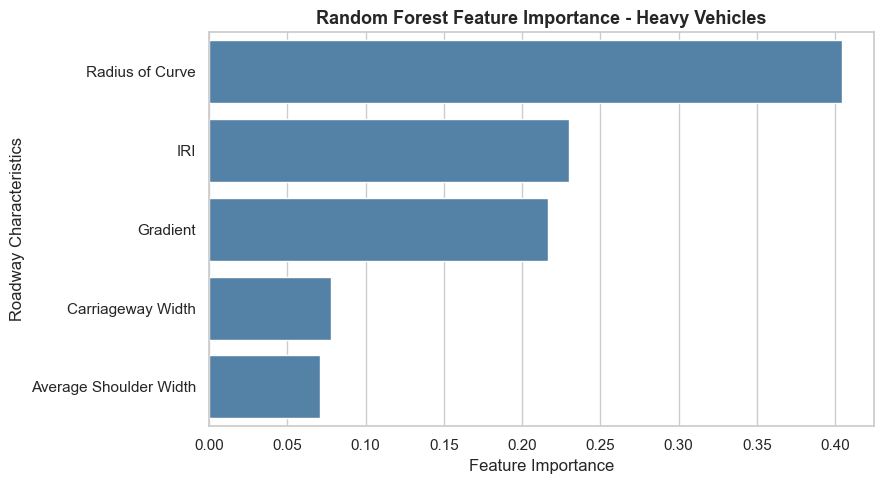

In [63]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Random Forest Feature Importance - Heavy Vehicles",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Roadway Characteristics")

plt.tight_layout()
plt.show()

In [64]:
param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

In [65]:
grid_xgb = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        importance_type="gain"
    ),
    param_grid=param_grid_xgb,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(X_train, y_train)

# Best model

best_xgb = grid_xgb.best_estimator_

print("Best XGBoost Parameters:")
print(grid_xgb.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-grid_xgb.best_score_)

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best XGBoost Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}

Best Cross-Validation RMSE:
6.836458778550115


In [66]:
# Predictions

y_pred_xgb = best_xgb.predict(X_test)

# Evaluation metrics

r2_xgb = r2_score(y_test, y_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

print("Tuned XGBoost Results")
print("----------------------")
print(f"R²   : {r2_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.4f} km/h")
print(f"MAE  : {mae_xgb:.4f} km/h")

Tuned XGBoost Results
----------------------
R²   : 0.5034
RMSE : 5.9806 km/h
MAE  : 5.0611 km/h


In [67]:
xgb_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_xgb.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print(xgb_importance)

                  Feature  Importance
1         Radius of Curve    0.426443
2       Carriageway Width    0.218066
4                     IRI    0.135910
3  Average Shoulder Width    0.111754
0                Gradient    0.107827


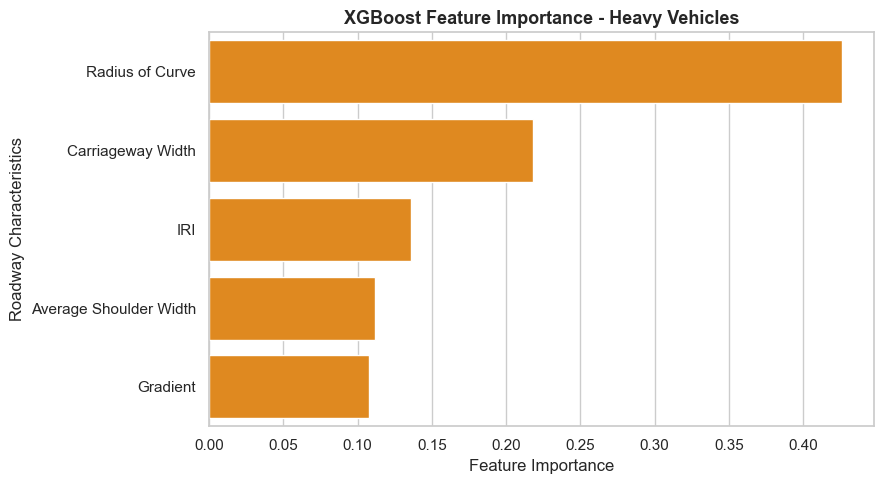

In [68]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=xgb_importance,
    x="Importance",
    y="Feature",
    color="darkorange"
)

plt.title(
    "XGBoost Feature Importance - Heavy Vehicles",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Roadway Characteristics")

plt.tight_layout()
plt.show()

In [69]:
pipeline_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

In [70]:
param_grid_svr = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.01, 0.1, 0.5, 1],
    "svr__gamma": ["scale", 0.01, 0.1, 1],
    "svr__kernel": ["rbf"]
}

In [71]:
grid_svr = GridSearchCV(
    estimator=pipeline_svr,
    param_grid=param_grid_svr,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_svr.fit(X_train, y_train)

# Best model

best_svr = grid_svr.best_estimator_

print("Best SVR Parameters:")
print(grid_svr.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-grid_svr.best_score_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best SVR Parameters:
{'svr__C': 100, 'svr__epsilon': 1, 'svr__gamma': 0.1, 'svr__kernel': 'rbf'}

Best Cross-Validation RMSE:
7.129193265844888


In [72]:
# Predictions

y_pred_svr = best_svr.predict(X_test)

# Evaluation metrics

r2_svr = r2_score(y_test, y_pred_svr)

rmse_svr = np.sqrt(
    mean_squared_error(y_test, y_pred_svr)
)

mae_svr = mean_absolute_error(y_test, y_pred_svr)

print("Tuned SVR Results")
print("------------------")
print(f"R²   : {r2_svr:.4f}")
print(f"RMSE : {rmse_svr:.4f} km/h")
print(f"MAE  : {mae_svr:.4f} km/h")

Tuned SVR Results
------------------
R²   : -0.0181
RMSE : 8.5634 km/h
MAE  : 7.0501 km/h


In [73]:
pipeline_ann = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPRegressor(
        random_state=42,
        max_iter=3000
    ))
])

In [74]:
param_grid_ann = {
    "ann__hidden_layer_sizes": [
        (32,),
        (64,),
        (64, 32),
        (128, 64)
    ],
    "ann__activation": ["relu", "tanh"],
    "ann__alpha": [0.0001, 0.001, 0.01],
    "ann__learning_rate_init": [0.001, 0.01]
}

In [75]:
grid_ann = GridSearchCV(
    estimator=pipeline_ann,
    param_grid=param_grid_ann,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_ann.fit(X_train, y_train)

# Best model

best_ann = grid_ann.best_estimator_

print("Best ANN Parameters:")
print(grid_ann.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-grid_ann.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best ANN Parameters:
{'ann__activation': 'tanh', 'ann__alpha': 0.01, 'ann__hidden_layer_sizes': (32,), 'ann__learning_rate_init': 0.001}

Best Cross-Validation RMSE:
7.410098894685656


In [76]:
# Predictions

y_pred_ann = best_ann.predict(X_test)

# Evaluation metrics

r2_ann = r2_score(y_test, y_pred_ann)

rmse_ann = np.sqrt(
    mean_squared_error(y_test, y_pred_ann)
)

mae_ann = mean_absolute_error(y_test, y_pred_ann)

print("Tuned ANN Results")
print("------------------")
print(f"R²   : {r2_ann:.4f}")
print(f"RMSE : {rmse_ann:.4f} km/h")
print(f"MAE  : {mae_ann:.4f} km/h")

Tuned ANN Results
------------------
R²   : 0.2405
RMSE : 7.3964 km/h
MAE  : 5.9987 km/h


In [77]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "SVR",
        "ANN"
    ],

    "R2": [
        r2_rf,
        r2_xgb,
        r2_svr,
        r2_ann
    ],

    "RMSE": [
        rmse_rf,
        rmse_xgb,
        rmse_svr,
        rmse_ann
    ],

    "MAE": [
        mae_rf,
        mae_xgb,
        mae_svr,
        mae_ann
    ]
})

results = results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\nHeavy Vehicle Model Comparison")
print(results.round(4))


Heavy Vehicle Model Comparison
           Model      R2    RMSE     MAE
0        XGBoost  0.5034  5.9806  5.0611
1  Random Forest  0.4191  6.4686  5.2704
2            ANN  0.2405  7.3964  5.9987
3            SVR -0.0181  8.5634  7.0501


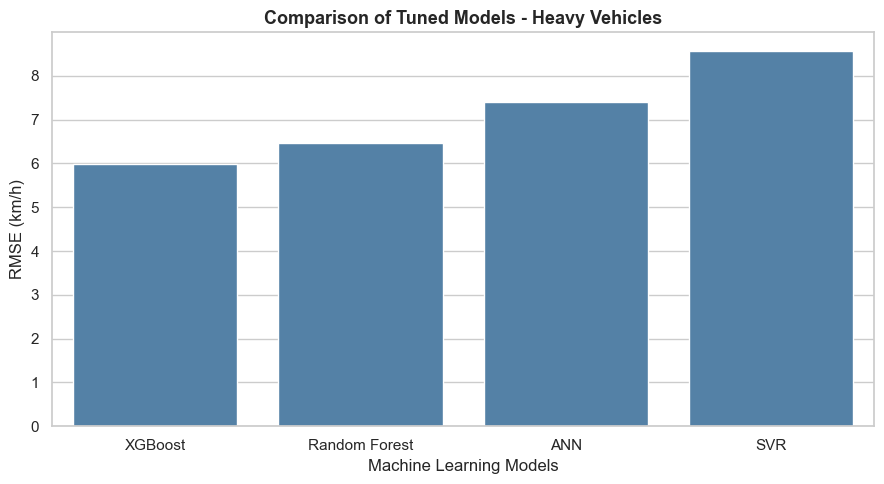

In [78]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE",
    color="steelblue"
)

plt.title(
    "Comparison of Tuned Models - Heavy Vehicles",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel("RMSE (km/h)")
plt.xlabel("Machine Learning Models")

plt.tight_layout()
plt.show()

In [80]:
importance_comparison = pd.DataFrame({
    "Feature": features,
    "Random Forest": best_rf.feature_importances_,
    "XGBoost": best_xgb.feature_importances_
})

print(importance_comparison.round(4))

                  Feature  Random Forest  XGBoost
0                Gradient         0.2166   0.1078
1         Radius of Curve         0.4045   0.4264
2       Carriageway Width         0.0779   0.2181
3  Average Shoulder Width         0.0712   0.1118
4                     IRI         0.2297   0.1359


In [81]:
# Save results

output_path = (
    r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE"
    r"\Vehicle Class wise\Heavy_Vehicle_Tuned_Model_Results.xlsx"
)

with pd.ExcelWriter(output_path) as writer:

    results.to_excel(
        writer,
        sheet_name="Model Comparison",
        index=False
    )

    importance_comparison.to_excel(
        writer,
        sheet_name="Feature Importance",
        index=False
    )

    predictions = pd.DataFrame({
        "Actual V85": y_test.values,
        "RF Predicted": y_pred_rf,
        "XGB Predicted": y_pred_xgb,
        "SVR Predicted": y_pred_svr,
        "ANN Predicted": y_pred_ann
    })

    predictions.to_excel(
        writer,
        sheet_name="Test Predictions",
        index=False
    )

    best_parameters = pd.DataFrame({
        "Model": [
            "Random Forest",
            "XGBoost",
            "SVR",
            "ANN"
        ],
        "Best Parameters": [
            str(grid_rf.best_params_),
            str(grid_xgb.best_params_),
            str(grid_svr.best_params_),
            str(grid_ann.best_params_)
        ],
        "Best CV RMSE": [
            -grid_rf.best_score_,
            -grid_xgb.best_score_,
            -grid_svr.best_score_,
            -grid_ann.best_score_
        ]
    })

    best_parameters.to_excel(
        writer,
        sheet_name="Best Parameters",
        index=False
    )

print("Results saved successfully!")

Results saved successfully!


In [84]:
from sklearn.linear_model import LinearRegression

# Train MLR baseline
mlr = LinearRegression()
mlr.fit(X_train, y_train)

# Predictions
y_pred_mlr = mlr.predict(X_test)

# Evaluation
r2_mlr = r2_score(y_test, y_pred_mlr)
rmse_mlr = np.sqrt(mean_squared_error(y_test, y_pred_mlr))
mae_mlr = mean_absolute_error(y_test, y_pred_mlr)

In [85]:
# Final comparison of all five models

model_comparison = pd.DataFrame({
    "Model": [
        "MLR",
        "Random Forest",
        "XGBoost",
        "SVR",
        "ANN"
    ],

    "R²": [
        r2_mlr,
        r2_rf,
        r2_xgb,
        r2_svr,
        r2_ann
    ],

    "RMSE (km/h)": [
        rmse_mlr,
        rmse_rf,
        rmse_xgb,
        rmse_svr,
        rmse_ann
    ],

    "MAE (km/h)": [
        mae_mlr,
        mae_rf,
        mae_xgb,
        mae_svr,
        mae_ann
    ]
})

# Sort according to RMSE (lowest is best)

model_comparison = model_comparison.sort_values(
    by="RMSE (km/h)",
    ascending=True
).reset_index(drop=True)

# Display results

print("\nHeavy Vehicle V85 Model Comparison")
print("-" * 65)

print(model_comparison.round(4).to_string(index=False))


Heavy Vehicle V85 Model Comparison
-----------------------------------------------------------------
        Model      R²  RMSE (km/h)  MAE (km/h)
      XGBoost  0.5034       5.9806      5.0611
Random Forest  0.4191       6.4686      5.2704
          MLR  0.2871       7.1659      5.8667
          ANN  0.2405       7.3964      5.9987
          SVR -0.0181       8.5634      7.0501


In [88]:
best_model = model_comparison.iloc[0]

print("\nBest Performing Model")
print("----------------------")

print("Model:", best_model["Model"])
print(f"R²: {best_model['R²']:.4f}")
print(f"RMSE: {best_model['RMSE (km/h)']:.4f} km/h")
print(f"MAE: {best_model['MAE (km/h)']:.4f} km/h")


Best Performing Model
----------------------
Model: XGBoost
R²: 0.5034
RMSE: 5.9806 km/h
MAE: 5.0611 km/h
